# Two point reflectors: Fabry–Pérot

The NumPy reference solver includes all scattering orders in a static scalar
fiber. Here we compare its complex fields with the closed two-mirror formula.
There are no Rayleigh samples in this example, so the analytic reference is
independent of their discretization. The right port is matched.

Run with Python, NumPy, Matplotlib, Jupyter and PyRayleigh installed, or from
this source checkout. All cells can be run in order. Section attenuation is
declared as **background power loss in 1/m**, not total measured attenuation.
We use float64 / complex128 throughout.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

repo = Path.cwd()
if repo.name == 'examples':
    repo = repo.parent
if (repo/'src'/'pyrayleigh').is_dir():
    sys.path.insert(0, str(repo/'src'))

import pyrayleigh
from pyrayleigh import (Fiber, FiberState, Field, FieldTerm, GuideOptics,
                       Probe, Section, SpatialProfile, lossless_reflector)
from pyrayleigh.constants import SPEED_OF_LIGHT as c
from pyrayleigh import compute_response

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('PyRayleigh', pyrayleigh.__version__, '| NumPy', np.__version__)
print('Backend: NumPy | parameter precision: float64 | fields: complex128')

PyRayleigh 0.1.0.dev0 | NumPy 2.5.4
Backend: NumPy | parameter precision: float64 | fields: complex128


For a uniform guide, the one-way factor over material length $d$ is

$$p(d)=e^{-\alpha d/2}e^{-i\beta_0 d}e^{-i\Delta\beta d},\quad
\beta_0=2\pi n\nu_0/c,\quad \Delta\beta=2\pi n_g(\nu-\nu_0)/c.$$

The two points are at $a$ and $b$. Write $p_0=p(a)$, $p_c=p(b-a)$,
$p_e=p(L-b)$ and $D=1-r_{A,R}r_{B,L}p_c^2$. The analytic fields are

$$r=p_0^2\left(r_{A,L}+\frac{t_{A,RL}t_{A,LR}r_{B,L}p_c^2}{D}\right),
\qquad t=\frac{p_0t_{A,LR}p_ct_{B,LR}p_e}{D}.$$

These functions use lengths, coefficients and the uniform guide equation
directly. They do not call `OpticalPath`, `TwoPort` or `star`.

In [2]:
n = ng = 1.46
nu0 = c/1550e-9
L, a = .01, .001
b = a + (1000+.25)*1550e-9/n
frequency = nu0 + np.linspace(-6e9, 6e9, 3001)
probe = Probe(frequency)
guide = GuideOptics(nu0, n, ng, gvd=0.)
beta0 = 2*np.pi*n*nu0/c
delta_beta = 2*np.pi*ng*(frequency-nu0)/c

def p(d, alpha, extra_length=0., frequencies=frequency):
    # Extra optical length changes phase, while loss stays on material length.
    detuning = 2*np.pi*ng*(frequencies-nu0)/c
    return (np.exp(-alpha*d/2)*np.exp(-1j*beta0*(d+extra_length))
            * np.exp(-1j*detuning*(d+extra_length)))

def analytic(A, B, alpha, extra=(0., 0., 0.), frequencies=frequency, length=L):
    p0 = p(A.position, alpha, extra[0], frequencies)
    pc = p(B.position-A.position, alpha, extra[1], frequencies)
    pe = p(length-B.position, alpha, extra[2], frequencies)
    denominator = 1.-A.r_right*B.r_left*pc**2
    r = p0**2*(A.r_left + A.t_right_to_left*A.t_left_to_right*B.r_left*pc**2/denominator)
    t = p0*A.t_left_to_right*pc*B.t_left_to_right*pe/denominator
    return r, t, denominator

def model(RA, RB, alpha):
    A, B = lossless_reflector(a, RA), lossless_reflector(b, RB)
    section = Section(0., L, guide, attenuation=alpha, rayleigh_coefficient=0.)
    fiber = Fiber('fp', L, 293.15, nu0-1e12, nu0+1e12, (section,), elements=(A, B))
    return fiber, A, B

field_atol, field_rtol, energy_atol = 2e-10, 2e-10, 3e-12
print(f'L={L:.6g} m, a={a:.6g} m, b={b:.12g} m, n=ng={n}')
print(f'nu0={nu0:.12g} Hz, {frequency.size} samples, step={frequency[1]-frequency[0]:.6g} Hz')
print(f'Field atol={field_atol:g}, rtol={field_rtol:g}; energy atol={energy_atol:g}')

L=0.01 m, a=0.001 m, b=0.00206190924658 m, n=ng=1.46
nu0=1.93414489032e+14 Hz, 3001 samples, step=4e+06 Hz
Field atol=2e-10, rtol=2e-10; energy atol=3e-12


## Weak and strong reflectors, with and without loss

The complex-field comparison includes phase. We also report the relative
L2 error of each field. For a lossless cavity, R+T must be one; with background
loss it must not exceed one. A small cascade-denominator cutoff only rejects
ill-conditioned arithmetic: it does not guarantee accuracy near every
high-Q resonance. These tolerances apply to the parameters and grid below.

In [3]:
cases = [('weak', .04, .09, 0.), ('strong', .99, .99, 0.), ('lossy', .9, .9, 2.)]
results = {}
print('case       max|dr|       max|dt|       rel L2(r)     rel L2(t)     min|D|       max(R+T)')
for name, RA, RB, alpha in cases:
    fiber, A, B = model(RA, RB, alpha)
    actual = compute_response(fiber, probe, method='exact', loss_convention='background')
    r, t, denominator = analytic(A, B, alpha)
    np.testing.assert_allclose(actual.reflection, r, atol=field_atol, rtol=field_rtol)
    np.testing.assert_allclose(actual.transmission, t, atol=field_atol, rtol=field_rtol)
    energy = abs(actual.reflection)**2+abs(actual.transmission)**2
    if alpha == 0.:
        np.testing.assert_allclose(energy, 1., atol=energy_atol, rtol=0.)
    else:
        assert np.all(energy <= 1.+energy_atol)
    dr, dt = actual.reflection-r, actual.transmission-t
    relative_r = np.linalg.norm(dr)/np.linalg.norm(r)
    relative_t = np.linalg.norm(dt)/np.linalg.norm(t)
    print(f'{name:8} {max(abs(dr)):.3e}    {max(abs(dt)):.3e}    {relative_r:.3e}    '
          f'{relative_t:.3e}    {min(abs(denominator)):.3e}    {max(energy):.12f}')
    results[name] = actual, r, t, energy

case       max|dr|       max|dt|       rel L2(r)     rel L2(t)     min|D|       max(R+T)
weak     2.012e-16    8.006e-16    5.337e-16    1.751e-16    9.400e-01    1.000000000000
strong   2.083e-14    2.066e-14    1.158e-15    5.641e-15    1.000e-02    1.000000000000
lossy    4.025e-15    3.848e-15    8.668e-16    1.154e-15    1.019e-01    0.992302713022


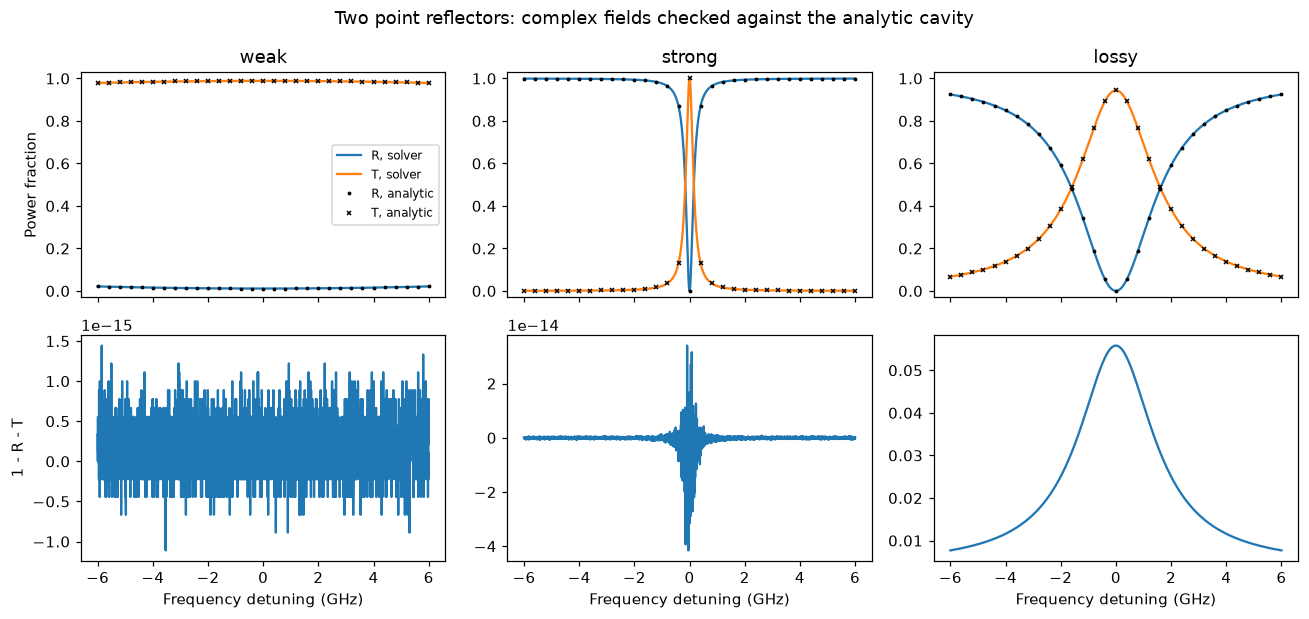

In [4]:
detuning = (frequency-nu0)/1e9
fig, axes = plt.subplots(2, 3, figsize=(12, 5.7), sharex=True)
for column, (name, _, _, _) in enumerate(cases):
    actual, r, t, energy = results[name]
    ax = axes[0, column]
    ax.plot(detuning, abs(actual.reflection)**2, label='R, solver')
    ax.plot(detuning, abs(actual.transmission)**2, label='T, solver')
    ax.plot(detuning[::100], abs(r[::100])**2, 'k.', ms=3, label='R, analytic')
    ax.plot(detuning[::100], abs(t[::100])**2, 'kx', ms=3, label='T, analytic')
    ax.set(title=name, ylim=(-.03, 1.03))
    axes[1, column].plot(detuning, 1.-energy)
    axes[1, column].set_xlabel('Frequency detuning (GHz)')
axes[0, 0].set_ylabel('Power fraction')
axes[1, 0].set_ylabel('1 - R - T')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Two point reflectors: complex fields checked against the analytic cavity')
fig.tight_layout()
plt.show()

## Local strain on the physical legs

Use the same two points and change only the static fiber state. This example
sets n=ng and zero GVD, with equal phase and group strain factors. A constant
strain epsilon over overlap length h adds `strain_factor * epsilon * h` to
that leg's phase length. Loss is still integrated over material position.

We compare the full cavity response for strain before A, between A and B,
and beyond B. The reflection cannot depend on strain beyond B in this
point-only model, but the transmitted phase does change there.

In [5]:
fiber, A, B = model(.9, .9, 0.)
epsilon = 1e-6
regions = {'before A': (.0002, .0008),
           'between A and B': (a+.2*(b-a), a+.8*(b-a)),
           'beyond B': (b+.001, b+.002)}
baseline = compute_response(fiber, probe, method='exact', loss_convention='background')
changed = {}
for name, (low, high) in regions.items():
    profile = SpatialProfile([low, high], [epsilon, epsilon])
    state = FiberState(axial_strain=Field((FieldTerm(profile),)))
    actual = compute_response(fiber, probe, state, method='exact', loss_convention='background')
    extra = tuple(guide.strain_phase_factor*epsilon*max(0., min(end, high)-max(start, low))
                  for start, end in ((0., a), (a, b), (b, L)))
    r, t, _ = analytic(A, B, 0., extra)
    np.testing.assert_allclose(actual.reflection, r, atol=field_atol, rtol=field_rtol)
    np.testing.assert_allclose(actual.transmission, t, atol=field_atol, rtol=field_rtol)
    changed[name] = actual
    print(f'{name:18} max|dr|={max(abs(actual.reflection-r)):.3e}, '
          f'max|dt|={max(abs(actual.transmission-t)):.3e}')

np.testing.assert_array_equal(changed['beyond B'].reflection, baseline.reflection)
assert max(abs(changed['beyond B'].transmission-baseline.transmission)) > 1e-4
print('Strain beyond B leaves reflection unchanged; transmission phase changes.')

before A           max|dr|=2.515e-15, max|dt|=2.410e-15
between A and B    max|dr|=2.180e-15, max|dt|=2.384e-15
beyond B           max|dr|=2.398e-15, max|dt|=2.248e-15
Strain beyond B leaves reflection unchanged; transmission phase changes.


The first repeated point path is $0\to b\to a\to b\to0$. Its physical
crossing counts are 2 before A, 4 inside the cavity and 0 beyond B. These
counts refer to this individual path, not the phase of the full multipath
sum. We check that path through the existing path evaluator separately.
Its apparent position $2b-a$ is not a propagation endpoint.

In [6]:
from pyrayleigh import point_reflection_paths, multiple_point_response

paths = point_reflection_paths(fiber, max_order=2)
assert tuple(path for path in paths if len(path) == 3) == ((1, 0, 1),)
reference_ghost = multiple_point_response(fiber, frequency, max_order=2)
beta = beta0+delta_beta
counts = (2, 4, 0)
for (name, (low, high)), crossings in zip(regions.items(), counts):
    profile = SpatialProfile([low, high], [epsilon, epsilon])
    state = FiberState(axial_strain=Field((FieldTerm(profile),)))
    actual_ghost = multiple_point_response(fiber, frequency, state, max_order=2)
    phase_change = -crossings*beta*guide.strain_phase_factor*epsilon*(high-low)
    np.testing.assert_allclose(actual_ghost/reference_ghost, np.exp(1j*phase_change), atol=2e-10, rtol=2e-10)
    print(f'{name:18} crossings={crossings}, phase change at nu0={phase_change[len(frequency)//2]:.6g} rad')

before A           crossings=2, phase change at nu0=-0.00553958 rad
between A and B    crossings=4, phase change at nu0=-0.0117651 rad
beyond B           crossings=0, phase change at nu0=0 rad


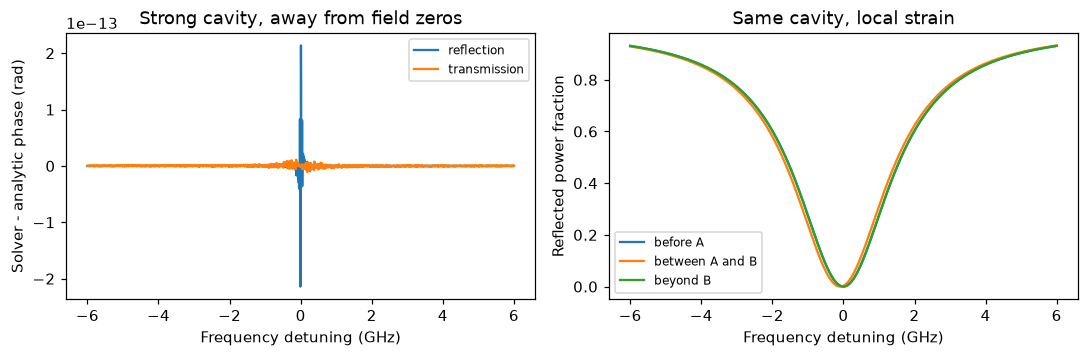

In [7]:
actual, r, t, _ = results['strong']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for field, reference, label in ((actual.reflection, r, 'reflection'), (actual.transmission, t, 'transmission')):
    # Reflection phase is undefined at an exact zero.
    mask = abs(reference) > 1e-6
    error = np.angle(field[mask]*np.conj(reference[mask]))
    axes[0].plot(detuning[mask], error, label=label)
for name, actual in changed.items():
    axes[1].plot(detuning, abs(actual.reflection)**2, label=name)
axes[0].set(xlabel='Frequency detuning (GHz)', ylabel='Solver - analytic phase (rad)', title='Strong cavity, away from field zeros')
axes[1].set(xlabel='Frequency detuning (GHz)', ylabel='Reflected power fraction', title='Same cavity, local strain')
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Full two-port: illuminate from both ends

Left power alone does not establish passivity for coherent illumination from
both ends. We assemble the complete S matrix by evaluating a point-only fiber
and its reversed copy. Reversal maps s to L-s, swaps r_L with r_R and swaps
t_LR with t_RL; it does not conjugate the point coefficients.

This additional uniform geometry uses lengths exactly representable in binary,
so reversing positions introduces no geometric round-off. There is no strain
or Rayleigh sample in this part. The right-incidence analytic fields are

$$r_R=p_e^2\left(r_{B,R}+\frac{t_{B,LR}t_{B,RL}r_{A,R}p_c^2}{D}\right),
\qquad t_{RL}=\frac{p_et_{B,RL}p_ct_{A,RL}p_0}{D}.$$

We compare all four fields, then check the largest singular value of S.
For lossless components we also check S-dagger S=I; for reciprocal components
we check t_LR=t_RL. An opaque first mirror is included.

In [8]:
from dataclasses import replace
from pyrayleigh import PointReflector

L2, a2, b2 = 1/64, 1/1024, 1/256
phase_B = (2*beta0*(b2-a2)-np.pi+.21) % (2*np.pi)
print('Two-port geometry (m):', L2, a2, b2)
print('case        max field error    max sigma(S)      max|S-dagger S-I|   max|tLR-tRL|')
for name, RA, RB, alpha in [('lossless', .7, .9, 0.), ('lossy', .7, .9, .5), ('opaque', 1., .9, 0.)]:
    A, B = lossless_reflector(a2, RA, .21), lossless_reflector(b2, RB, phase_B)
    fiber2 = Fiber(name, L2, 293.15, nu0-1e12, nu0+1e12,
                   (Section(0., L2, guide, alpha, 0.),), elements=(A, B))
    reversed_points = tuple(PointReflector(L2-point.position, point.r_right, point.r_left,
                           point.t_right_to_left, point.t_left_to_right) for point in fiber2.elements)
    reversed_fiber = replace(fiber2, elements=reversed_points)
    left = compute_response(fiber2, probe, method='exact', loss_convention='background')
    right = compute_response(reversed_fiber, probe, method='exact', loss_convention='background')
    S = np.stack((np.stack((left.reflection, right.transmission), axis=-1),
                  np.stack((left.transmission, right.reflection), axis=-1)), axis=-2)
    r, t, denominator = analytic(A, B, alpha, length=L2)
    p0, pc, pe = p(a2, alpha), p(b2-a2, alpha), p(L2-b2, alpha)
    r_right = pe**2*(B.r_right+B.t_left_to_right*B.t_right_to_left*A.r_right*pc**2/denominator)
    t_reverse = pe*B.t_right_to_left*pc*A.t_right_to_left*p0/denominator
    reference = np.stack((np.stack((r, t_reverse), axis=-1), np.stack((t, r_right), axis=-1)), axis=-2)
    np.testing.assert_allclose(S, reference, atol=field_atol, rtol=field_rtol)
    largest = np.linalg.svd(S, compute_uv=False)[..., 0]
    identity_error = np.max(abs(S.conj().swapaxes(-1, -2)@S-np.eye(2)))
    reciprocity_error = np.max(abs(left.transmission-right.transmission))
    assert np.max(largest) <= 1.+energy_atol
    if alpha == 0.:
        assert identity_error <= energy_atol
    np.testing.assert_allclose(left.transmission, right.transmission, atol=energy_atol, rtol=0.)
    print(f'{name:10} {np.max(abs(S-reference)):.3e}          {np.max(largest):.12f}    '
          f'{identity_error:.3e}           {reciprocity_error:.3e}')

Two-port geometry (m): 0.015625 0.0009765625 0.00390625
case        max field error    max sigma(S)      max|S-dagger S-I|   max|tLR-tRL|
lossless   1.968e-15          1.000000000000    4.885e-15           1.066e-15
lossy      3.133e-15          0.998996017923    2.406e-02           1.030e-15
opaque     7.100e-15          1.000000000000    1.743e-14           0.000e+00


## Resolve a narrow resonance

Keep the physical cavity and the 12 GHz band fixed, with equal power
reflectivities R=0.9999 and no loss. A phase on B moves the resonance away
from the grid centre. Only the number of frequency samples changes.

The analytic free spectral range is FSR=c/(2 n_g d). The power FWHM is

$$\Delta\nu_{1/2}=\frac{2\,\mathrm{FSR}}{\pi}
\arcsin\frac{1-R}{2\sqrt{R}}.$$

Peak power and FWHM are measured on each grid, with linear interpolation of
the half-power crossings. A coarse grid can miss the peak completely;
`unresolved` means that no half-power width could be measured on that grid.
This is a sampling check: fields at a shared frequency must agree. It is not
Rayleigh-grid convergence, nor an adaptive optical solver.

The analytic reference is still float64. Near a resonance, division amplifies
round-off approximately as 1/|D|. We record min|D| and use absolute field
tolerance `field_atol + 256*eps/min|D|`, and energy tolerance
`energy_atol + 512*eps/min|D|`. These are allowances for this example, not a
general high-Q accuracy guarantee or a replacement for higher precision.

In [9]:
R = .9999
fine_fiber, A, B = model(R, R, 0.)
B = lossless_reflector(b, R, phase=.137)
fine_fiber = replace(fine_fiber, elements=(A, B))
fsr = c/(2*ng*(b-a))
expected_width = 2*fsr/np.pi*np.arcsin((1-R)/(2*np.sqrt(R)))
phase_at_reference = np.angle(A.r_right*B.r_left*np.exp(-2j*beta0*(b-a)))
peak_frequency = nu0+phase_at_reference*fsr/(2*np.pi)

def width_at_half_power(frequencies, power):
    above = np.flatnonzero(power >= .5)
    if len(above) == 0 or above[0] == 0 or above[-1] == len(power)-1:
        return np.nan
    i, j = above[0], above[-1]
    low = np.interp(.5, power[i-1:i+1], frequencies[i-1:i+1])
    high = np.interp(.5, power[j:j+2][::-1], frequencies[j:j+2][::-1])
    return high-low

print(f'R={R}, FSR={fsr/1e9:.9g} GHz, analytic FWHM={expected_width/1e6:.9g} MHz')
print(f'Peak detuning={(peak_frequency-nu0)/1e9:.9g} GHz; default denominator cutoff={64*np.finfo(float).eps:.3e}')
print('N        step (MHz)   max T       FWHM (MHz)   min|D|     max field error   rel L2(t)   max phase error (rad)')
sampling = []
previous = None
for count in (1501, 6001, 24001, 96001):
    grid = nu0+np.linspace(-6e9, 6e9, count)
    actual = compute_response(fine_fiber, Probe(grid), method='exact', loss_convention='background')
    r, t, denominator = analytic(A, B, 0., frequencies=grid)
    cutoff = np.min(abs(denominator))
    allowance = field_atol+256*np.finfo(float).eps/cutoff
    np.testing.assert_allclose(actual.reflection, r, atol=allowance, rtol=field_rtol)
    np.testing.assert_allclose(actual.transmission, t, atol=allowance, rtol=field_rtol)
    energy = abs(actual.reflection)**2+abs(actual.transmission)**2
    np.testing.assert_allclose(energy, 1., atol=energy_atol+512*np.finfo(float).eps/cutoff, rtol=0.)
    if previous is not None:
        old_grid, old_response = previous
        np.testing.assert_array_equal(grid[::4], old_grid)
        np.testing.assert_allclose(actual.reflection[::4], old_response.reflection, atol=allowance, rtol=field_rtol)
        np.testing.assert_allclose(actual.transmission[::4], old_response.transmission, atol=allowance, rtol=field_rtol)
    previous = grid, actual
    power = abs(actual.transmission)**2
    width = width_at_half_power(grid, power)
    error = max(np.max(abs(actual.reflection-r)), np.max(abs(actual.transmission-t)))
    relative = np.linalg.norm(actual.transmission-t)/max(np.linalg.norm(t), 1e-12)
    mask = abs(t) > 1e-6
    phase_error = np.max(abs(np.angle(actual.transmission[mask]*np.conj(t[mask]))))
    step = grid[1]-grid[0]
    width_label = f'{width/1e6:.5f}' if np.isfinite(width) else 'unresolved'
    print(f'{count:6}   {step/1e6:8.3f}    {max(power):.6f}    {width_label:>10}    '
          f'{cutoff:.3e}  {error:.3e}        {relative:.3e}    {phase_error:.3e}')
    sampling.append((grid, power, step, width))

assert abs(sampling[-1][3]/expected_width-1.) < .01
assert max(sampling[-1][1]) > .99
print('Finest grid: peak power and half-power width agree within 1%; shared sample fields are unchanged.')

R=0.9999, FSR=96.6830737 GHz, analytic FWHM=3.07767171 MHz
Peak detuning=2.10809971 GHz; default denominator cutoff=1.421e-14
N        step (MHz)   max T       FWHM (MHz)   min|D|     max field error   rel L2(t)   max phase error (rad)
  1501      8.000    0.134697    unresolved    2.725e-04  1.539e-13        2.733e-13    3.426e-13
  6001      2.000    0.995819       3.18748    1.002e-04  1.106e-12        7.721e-13    6.210e-13


 24001      0.500    0.995819       3.10229    1.002e-04  1.106e-12        6.150e-13    8.201e-13


 96001      0.125    0.999730       3.07944    1.000e-04  1.453e-12        6.873e-13    1.244e-12
Finest grid: peak power and half-power width agree within 1%; shared sample fields are unchanged.


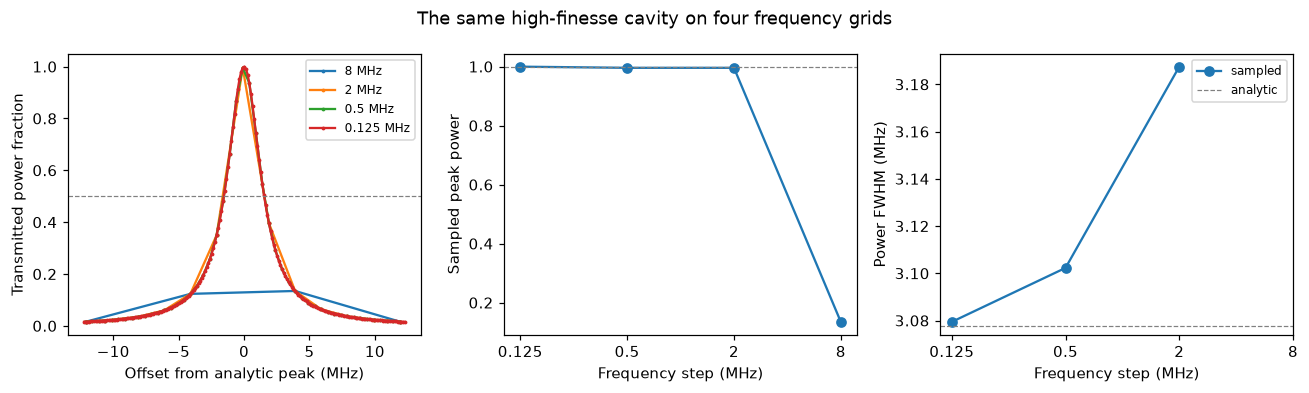

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for grid, power, step, width in sampling:
    near = abs(grid-peak_frequency) <= 4*expected_width
    axes[0].plot((grid[near]-peak_frequency)/1e6, power[near], '.-', ms=3, label=f'{step/1e6:g} MHz')
steps = np.array([row[2] for row in sampling])/1e6
axes[0].axhline(.5, color='gray', lw=.8, ls='--')
axes[0].set(xlabel='Offset from analytic peak (MHz)', ylabel='Transmitted power fraction')
axes[0].legend(fontsize=8)
axes[1].semilogx(steps, [max(row[1]) for row in sampling], 'o-')
axes[1].axhline(1., color='gray', lw=.8, ls='--')
axes[1].set(xlabel='Frequency step (MHz)', ylabel='Sampled peak power')
axes[2].semilogx(steps, [row[3]/1e6 for row in sampling], 'o-', label='sampled')
axes[2].axhline(expected_width/1e6, color='gray', lw=.8, ls='--', label='analytic')
axes[2].set(xlabel='Frequency step (MHz)', ylabel='Power FWHM (MHz)')
axes[2].legend(fontsize=8)
for ax in axes[1:]:
    ax.set_xticks(steps, labels=[f'{step:g}' for step in steps])
    ax.minorticks_off()
fig.suptitle('The same high-finesse cavity on four frequency grids')
fig.tight_layout()
plt.show()

This checks a finite scalar static cavity. It does not validate Rayleigh-grid
convergence, distributed Bragg gratings, time-dependent propagation, multicore
coupling or a JAX implementation. The all-orders reference is selected through
`compute_response(..., method="exact", loss_convention="background")`.
Omitting `method` keeps the earlier truncated model and its `max_order` behavior.
An explicit `max_order` is rejected for the exact method.